In [1]:
from google.colab import files

uploaded = files.upload()

Saving tickets_labelled.xlsx to tickets_labelled.xlsx


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_excel("tickets_labelled.xlsx")

print(df.head())

  ticket_id                        title  \
0     T0001  Search results not relevant   
1     T0002         Change button colour   
2     T0003        Font too small on FAQ   
3     T0004  Production site not loading   
4     T0005         Change button colour   

                                         description channel  priority  
0  Searching for "mouse" shows bedsheets first Ur...  Portal    Medium  
1  Please make the Save button blue to match the ...    Chat       Low  
2  FAQ answers are hard to read on mobile Raised ...   Phone       Low  
3  The main website shows a 500 error for every u...   Phone  Critical  
4  Please make the Save button blue to match the ...    Chat       Low  


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nPriority Distribution:")
print(df["priority"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nPriority Categories:")
print(df["priority"].unique())

Dataset Shape: (800, 5)

Column Names:
['ticket_id', 'title', 'description', 'channel', 'priority']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ticket_id    800 non-null    object
 1   title        800 non-null    object
 2   description  800 non-null    object
 3   channel      800 non-null    object
 4   priority     800 non-null    object
dtypes: object(5)
memory usage: 31.4+ KB

Priority Distribution:
priority
Medium      304
Low         244
High        183
Critical     69
Name: count, dtype: int64

Missing Values:
ticket_id      0
title          0
description    0
channel        0
priority       0
dtype: int64

Duplicate Rows: 0

Priority Categories:
['Medium' 'Low' 'Critical' 'High']


In [5]:
# Combine text columns
df["text"] = (
    df["title"].astype(str) + " " +
    df["description"].astype(str) + " " +
    df["channel"].astype(str)
)

# Input and target
X = df["text"]
y = df["priority"]

print("Input Samples:")
print(X.head())

print("\nTarget Labels:")
print(y.head())

Input Samples:
0    Search results not relevant Searching for "mou...
1    Change button colour Please make the Save butt...
2    Font too small on FAQ FAQ answers are hard to ...
3    Production site not loading The main website s...
4    Change button colour Please make the Save butt...
Name: text, dtype: object

Target Labels:
0      Medium
1         Low
2         Low
3    Critical
4         Low
Name: priority, dtype: object


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Priority Distribution:")
print(y_train.value_counts())

print("\nTesting Priority Distribution:")
print(y_test.value_counts())

Training Samples: 640
Testing Samples: 160

Training Priority Distribution:
priority
Medium      243
Low         195
High        147
Critical     55
Name: count, dtype: int64

Testing Priority Distribution:
priority
Medium      61
Low         49
High        36
Critical    14
Name: count, dtype: int64


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

Create the TF-IDF + Logistic Regression Pipeline

In [8]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

In [9]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [10]:
y_pred = model.predict(X_test)

print("Actual Priorities:")
print(y_test.head(10).tolist())

print("\nPredicted Priorities:")
print(y_pred[:10].tolist())

Actual Priorities:
['Medium', 'Low', 'Low', 'Medium', 'Medium', 'Low', 'Medium', 'Critical', 'High', 'Medium']

Predicted Priorities:
['Medium', 'Low', 'Low', 'Medium', 'Medium', 'Low', 'High', 'Critical', 'High', 'Medium']


Stratified Cross-Validation and Evaluation Metrics

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

Configure 5-fold Stratified Cross-Validation

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}

Perform cross-validation

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use built-in multiclass scoring metrics
scoring = {
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Perform cross-validation
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

# Display individual fold results
for i in range(5):
    print(f"\nFold {i+1}")
    print(f"Precision: {cv_results['test_precision'][i]:.4f}")
    print(f"Recall: {cv_results['test_recall'][i]:.4f}")
    print(f"F1-Score: {cv_results['test_f1'][i]:.4f}")

# Display average scores
print("\nAverage Cross-Validation Scores")
print(f"Precision: {cv_results['test_precision'].mean():.4f}")
print(f"Recall: {cv_results['test_recall'].mean():.4f}")
print(f"F1-Score: {cv_results['test_f1'].mean():.4f}")


Fold 1
Precision: 0.9596
Recall: 0.9479
F1-Score: 0.9524

Fold 2
Precision: 0.9388
Recall: 0.9174
F1-Score: 0.9272

Fold 3
Precision: 0.9273
Recall: 0.9412
F1-Score: 0.9338

Fold 4
Precision: 0.9573
Recall: 0.9405
F1-Score: 0.9483

Fold 5
Precision: 0.9477
Recall: 0.9297
F1-Score: 0.9381

Average Cross-Validation Scores
Precision: 0.9462
Recall: 0.9354
F1-Score: 0.9400


Display individual fold results

In [31]:
for i in range(5):
    print(f"\nFold {i+1}")
    print("Precision:", cv_results["test_precision"][i])
    print("Recall:", cv_results["test_recall"][i])
    print("F1-Score:", cv_results["test_f1"][i])


Fold 1
Precision: 0.9596248114630468
Recall: 0.9479166666666667
F1-Score: 0.9523729610754927

Fold 2
Precision: 0.9388314785373609
Recall: 0.917416958041958
F1-Score: 0.9272100706311233

Fold 3
Precision: 0.9272629310344828
Recall: 0.941206576674557
F1-Score: 0.9337972766194222

Fold 4
Precision: 0.957323187895848
Recall: 0.9405254023480625
F1-Score: 0.9483456411809595

Fold 5
Precision: 0.9477276746242264
Recall: 0.9296942794479741
F1-Score: 0.9381461450426967


In [32]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=["Critical", "High", "Medium", "Low"],
    zero_division=0
))

              precision    recall  f1-score   support

    Critical       0.92      0.86      0.89        14
        High       0.85      0.81      0.83        36
      Medium       0.89      0.89      0.89        61
         Low       0.92      0.98      0.95        49

    accuracy                           0.89       160
   macro avg       0.90      0.88      0.89       160
weighted avg       0.89      0.89      0.89       160



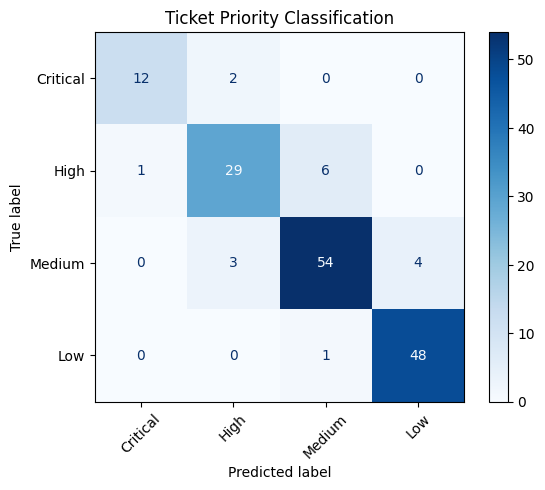

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Critical", "High", "Medium", "Low"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(cmap="Blues", xticks_rotation=45)
plt.title("Ticket Priority Classification")
plt.show()

# Error Analysis on 20 Misclassified Tickets

Create an error analysis DataFrame

In [34]:
# Create a DataFrame with actual and predicted priorities
results = pd.DataFrame({
    "ticket_id": df.loc[X_test.index, "ticket_id"],
    "title": df.loc[X_test.index, "title"],
    "description": df.loc[X_test.index, "description"],
    "channel": df.loc[X_test.index, "channel"],
    "actual_priority": y_test,
    "predicted_priority": y_pred
})

# Select incorrectly classified tickets
misclassified = results[
    results["actual_priority"] != results["predicted_priority"]
]

print("Total Misclassified Tickets:", len(misclassified))

Total Misclassified Tickets: 17


In [21]:
from IPython.display import display

# Display all 17 misclassified tickets
display(misclassified)

# Count errors by actual and predicted priority
print("\nError Distribution:")

print(
    misclassified.groupby(
        ["actual_priority", "predicted_priority"]
    ).size()
)

,ticket_id,title,description,channel,actual_priority,predicted_priority
140,T0141,Slow checkout,Checkout takes over 30 seconds during evening hours Not sure if it's related.,Phone,Medium,High
738,T0739,Add dark mode,Request to add a dark mode option in settings Not sure if it's related.,Phone,Medium,Low
292,T0293,Email notifications delayed,Order confirmation emails arrive an hour late Please help.,Chat,High,Medium
409,T0410,Orders not syncing to warehouse,"No orders have reached the warehouse system since last night, dispatch is blocked",Portal,High,Critical
728,T0729,Wrong delivery date shown,Order O100132 shows the wrong expected delivery date Raised by support team.,Email,High,Medium
51,T0052,Report export slow,The monthly sales export takes 5 minutes Seen since morning.,Chat,High,Medium
221,T0222,Wrong delivery date shown,Order O100895 shows the wrong expected delivery date Not sure if it's related.,Phone,High,Medium
451,T0452,Search results not relevant,"Searching for ""mouse"" shows bedsheets first Thanks.",Phone,Low,Medium
179,T0180,Profile photo upload fails,Uploading a PNG profile photo shows an error Seen since morning.,Chat,High,Medium
234,T0235,Invoice amounts wrong,GST is calculated twice on invoices for some orders Not sure if it's related.,Portal,Critical,High



Error Distribution:
actual_priority  predicted_priority
Critical         High                  2
High             Critical              1
                 Medium                6
Low              Medium                1
Medium           High                  3
                 Low                   4
dtype: int64


In [22]:
misclassified.to_excel(
    "ticket_error_analysis.xlsx",
    index=False
)

from google.colab import files
files.download("ticket_error_analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

save the trained model

In [35]:
import joblib

joblib.dump(model, "ticket_priority_model.pkl")

print("Model saved successfully!")

Model saved successfully!


test whether saved modle works

In [36]:
loaded_model = joblib.load("ticket_priority_model.pkl")

sample_ticket = [
    "Unable to login to my account. Payment failed and urgent assistance required."
]

prediction = loaded_model.predict(sample_ticket)

print("Predicted Priority:", prediction[0])

Predicted Priority: Critical


prepare model matrix

In [25]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("Accuracy:", accuracy)
print("Macro Precision:", macro_precision)
print("Macro Recall:", macro_recall)
print("Macro F1-Score:", macro_f1)

Accuracy: 0.89375
Macro Precision: 0.8960852310659447
Macro Recall: 0.8818840377681126
Macro F1-Score: 0.8883003171511531


create model card

In [26]:
model_card = f"""
# MODEL CARD: Support Ticket Priority Classification

## 1. Model Name
TF-IDF + Logistic Regression

## 2. Model Purpose
Classifies support tickets into four priority categories:
Critical, High, Medium, and Low.

## 3. Dataset Information
Dataset: tickets_labelled.xlsx
Total Records: 800
Training Records: 640
Testing Records: 160

Input Features:
- Ticket Title
- Ticket Description
- Channel

Target:
- Priority

## 4. Model Architecture
- TF-IDF Vectorizer
- Logistic Regression
- Class Weight: Balanced
- Random State: 42

## 5. Evaluation Metrics
Accuracy: {accuracy:.4f}
Macro Precision: {macro_precision:.4f}
Macro Recall: {macro_recall:.4f}
Macro F1-Score: {macro_f1:.4f}

## 6. Error Analysis
Misclassified Tickets: {len(misclassified)}
Total Test Tickets: {len(y_test)}

## 7. Limitations
- Performance depends on the quality of labelled tickets.
- Critical tickets have fewer training examples.
- Ambiguous descriptions may cause incorrect predictions.
- The model may not understand complex context or sarcasm.
- Predictions should be reviewed by a human before making important decisions.

## 8. Intended Use
This model is a classic machine learning baseline
for support ticket priority classification.

It can be compared with future LLM-based
classification approaches.
"""

with open("MODEL_CARD.md", "w") as file:
    file.write(model_card)

print(model_card)


# MODEL CARD: Support Ticket Priority Classification

## 1. Model Name
TF-IDF + Logistic Regression

## 2. Model Purpose
Classifies support tickets into four priority categories:
Critical, High, Medium, and Low.

## 3. Dataset Information
Dataset: tickets_labelled.xlsx
Total Records: 800
Training Records: 640
Testing Records: 160

Input Features:
- Ticket Title
- Ticket Description
- Channel

Target:
- Priority

## 4. Model Architecture
- TF-IDF Vectorizer
- Logistic Regression
- Class Weight: Balanced
- Random State: 42

## 5. Evaluation Metrics
Accuracy: 0.8938
Macro Precision: 0.8961
Macro Recall: 0.8819
Macro F1-Score: 0.8883

## 6. Error Analysis
Misclassified Tickets: 17
Total Test Tickets: 160

## 7. Limitations
- Performance depends on the quality of labelled tickets.
- Critical tickets have fewer training examples.
- Ambiguous descriptions may cause incorrect predictions.
- The model may not understand complex context or sarcasm.
- Predictions should be reviewed by a human be

download model and model card

In [27]:
from google.colab import files

files.download("ticket_priority_model.pkl")
files.download("MODEL_CARD.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>